# 04 — Correct probability calibration and independently verify

The previously inspected test period is retired from model selection. Use the original training period for coefficients and split validation dates into an earlier calibration portion and a later model-selection portion. Compare linear calendar extrapolation, seasonality without a linear trend, and no calendar effects. For each, compare raw probabilities with global and seller-group sigmoid corrections. Lock the method using later-validation log loss; then fit only the chosen correction on the full validation period.

First-stage diagnostic evaluation uses five newly generated 50,000-vehicle datasets using seeds 16940–16944. The first stage remained undercalibrated; a second stage below uses new calibration/selection cohorts and fresh final evaluation seeds. **Keep the original simulator coefficients, intercept adjustments, and price multipliers fixed.** Only random draws change. Evaluate the dates after the original validation endpoint. This is a probability-repair evaluation with fixed trained models, not the final 30-replication model-refitting policy study.

All outputs belong to `data/`; no employer data or changes to Larsen assets. The old test results remain available as the reason this diagnostic work was initiated, not as independent confirmation.


In [1]:
from pathlib import Path
import json, hashlib, time, warnings, platform, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.special import expit, logit
from scipy.optimize import brentq
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, brier_score_loss, roc_auc_score
import cloudpickle, joblib
BASE=Path('data/training/binding_historical')
OUT=Path('data/training/calibration_repair'); OUT.mkdir(parents=True,exist_ok=True)
CAL=Path('data/calibration')
metadata=json.loads((CAL/'calibration_metadata.json').read_text())
CONFIG=metadata['config'].copy()
SEEDS=list(range(16940,16945))
SEED=6940;MIN_CATEGORY_COUNT=100
train=pd.read_csv(BASE/'train.csv',parse_dates=['auction_date'])
validation=pd.read_csv(BASE/'validation.csv',parse_dates=['auction_date'])
with (BASE/'selected_models.pkl').open('rb') as f: original=cloudpickle.load(f)
origin=train.auction_date.min()
parts={'train':train,'validation':validation}
count=validation.groupby('auction_date').size().cumsum()
calibration_cut=(count-len(validation)/2).abs().idxmin()
calibration=validation.loc[validation.auction_date.le(calibration_cut)].copy()
selection=validation.loc[validation.auction_date.gt(calibration_cut)].copy()
assert calibration.auction_date.max()<selection.auction_date.min()
assert selection.auction_date.max()==validation.auction_date.max()
print('Calibration rows:',len(calibration),'Selection rows:',len(selection))


Calibration rows: 5002 Selection rows: 4990


In [2]:
NUMERIC=['age','log_mileage','log_benchmark','calendar_days','month_sin','month_cos']
CATEGORICAL=['make','condition','location','seller_group']
FEATURES=NUMERIC+['floor_ratio']+CATEGORICAL
FORBIDDEN={'sold','price','high_bid','bargaining_accepted_below_floor','vehicle_id','run_id',
           'private_signal','market_shock','sale_uniform','true_sale_probability_given_latents'}
assert not set(FEATURES)&FORBIDDEN
origin=parts['train'].auction_date.min()

def features(d):
    x=d[['age','mileage','benchmark','floor_ratio']+CATEGORICAL].copy()
    x['log_mileage']=np.log1p(x.mileage)
    x['log_benchmark']=np.log(x.benchmark)
    x['calendar_days']=(pd.to_datetime(d.auction_date)-origin).dt.days
    month=pd.to_datetime(d.auction_date).dt.month
    x['month_sin']=np.sin(2*np.pi*month/12)
    x['month_cos']=np.cos(2*np.pi*month/12)
    for col in CATEGORICAL: x[col]=x[col].fillna('<missing>').astype(str)
    return x[FEATURES]

class RestrictedCubicSpline(BaseEstimator,TransformerMixin):
    def __init__(self, quantiles=(.05,.35,.65,.95)):
        self.quantiles=quantiles
    def fit(self,X,y=None):
        values=np.asarray(X,dtype=float).reshape(-1)
        self.knots_=np.quantile(values,self.quantiles)
        if len(np.unique(self.knots_))!=len(self.knots_):
            raise ValueError('Spline knots must be distinct')
        return self
    def transform(self,X):
        a=np.asarray(X,dtype=float).reshape(-1)
        k=self.knots_; positive=lambda z:np.maximum(z,0)**3
        basis=[a]
        for knot in k[:-2]:
            term=(positive(a-knot)-positive(a-k[-2])*(k[-1]-knot)/(k[-1]-k[-2])
                  +positive(a-k[-1])*(k[-2]-knot)/(k[-1]-k[-2]))/(k[-1]-k[0])**2
            basis.append(term)
        return np.column_stack(basis)

def preprocessing(knots=None):
    floor_steps=[('imputer',SimpleImputer(strategy='median'))]
    if knots is not None: floor_steps.append(('spline',RestrictedCubicSpline(knots)))
    floor_steps.append(('scale',StandardScaler()))
    return ColumnTransformer([
       ('numeric',make_pipeline(SimpleImputer(strategy='median',add_indicator=True),StandardScaler()),NUMERIC),
       ('floor',Pipeline(floor_steps),['floor_ratio']),
       ('categories',OneHotEncoder(handle_unknown='infrequent_if_exist',min_frequency=MIN_CATEGORY_COUNT,sparse_output=False),CATEGORICAL)],sparse_threshold=0)


## Select the remedy using development data only

Sigmoid correction regresses the sale outcome on predicted log odds. The group version permits separate slopes and intercepts for dealer and fleet/lease records. Calibration coefficients are fitted on earlier validation dates, and alternatives are scored on later validation dates. The final selected correction is then refitted on all validation dates. Model training does not use validation outcomes.


In [3]:
Xtrain=features(train); Xcal=features(calibration); Xselect=features(selection)
variants={}; feature_specs={}; rows=[]
base_numeric=NUMERIC.copy()
for name,columns in [('linear_time',base_numeric),
                     ('seasonal_only',[v for v in base_numeric if v!='calendar_days']),
                     ('no_calendar',[v for v in base_numeric if v not in ['calendar_days','month_sin','month_cos']])]:
    NUMERIC=columns
    model=make_pipeline(preprocessing((.10,.50,.90)),LogisticRegression(C=1.0,max_iter=2000,random_state=SEED))
    model.fit(Xtrain,train.sold)
    variants[name]=model;feature_specs[name]=columns.copy()
NUMERIC=base_numeric

def fit_correction(mode,q,groups,y):
    if mode=='raw':return {'mode':mode}
    result={'mode':mode,'models':{}}
    keys=['all'] if mode=='global_sigmoid' else sorted(pd.Series(groups).unique())
    groups=np.asarray(groups);y=np.asarray(y)
    for key in keys:
        use=np.ones(len(q),dtype=bool) if key=='all' else groups==key
        m=LogisticRegression(C=1000,max_iter=1000)
        m.fit(logit(np.clip(q[use],1e-8,1-1e-8)).reshape(-1,1),y[use])
        result['models'][key]=m
    return result

def correct(correction,q,groups):
    if correction['mode']=='raw':return q
    result=np.empty(len(q));groups=np.asarray(groups)
    for key,m in correction['models'].items():
        use=np.ones(len(q),dtype=bool) if key=='all' else groups==key
        if not use.any():
            continue
        result[use]=m.predict_proba(logit(np.clip(q[use],1e-8,1-1e-8)).reshape(-1,1))[:,1]
    if correction['mode']=='group_sigmoid' and not set(groups)<=set(correction['models']):
        raise ValueError('Unseen seller group requires an explicit calibration rule')
    return result

for name,m in variants.items():
    qa=m.predict_proba(Xcal)[:,1];qb=m.predict_proba(Xselect)[:,1]
    for mode in ['raw','global_sigmoid','group_sigmoid']:
        correction=fit_correction(mode,qa,calibration.seller_group,calibration.sold)
        q=correct(correction,qb,selection.seller_group)
        rows.append(dict(variant=name,correction=mode,log_loss=log_loss(selection.sold,q),
             brier=brier_score_loss(selection.sold,q),mean_predicted=q.mean(),observed=selection.sold.mean()))
comparison=pd.DataFrame(rows).sort_values('log_loss')
choice=comparison.iloc[0]
selected=variants[choice.variant]
locked_correction=fit_correction(choice.correction,selected.predict_proba(features(validation))[:,1],validation.seller_group,validation.sold)
comparison.to_csv(OUT/'development_selection.csv',index=False)
display(comparison)
print('Locked:',choice.variant,choice.correction)

class CalibratedSaleModel:
    def __init__(self,model,correction):self.model=model;self.correction=correction
    def predict_proba(self,x):
        q=correct(self.correction,self.model.predict_proba(x)[:,1],x.seller_group)
        return np.column_stack([1-q,q])
repaired=CalibratedSaleModel(selected,locked_correction)
# Quantify the original fitted calendar trend on the raw log-odds scale.
old_model=original['classifier'];prep=old_model.steps[0][1]
scale=prep.named_transformers_['numeric'].steps[-1][1].scale_[3]
trend=float(old_model.steps[-1][1].coef_[0,3]/scale)
print('Original linear calendar coefficient (log odds/year):',trend*365.25)


,variant,correction,log_loss,brier,mean_predicted,observed
3,seasonal_only,raw,0.507653,0.168204,0.521618,0.541483
4,seasonal_only,global_sigmoid,0.511274,0.169737,0.494127,0.541483
5,seasonal_only,group_sigmoid,0.511603,0.169809,0.490618,0.541483
6,no_calendar,raw,0.513594,0.170640,0.493185,0.541483
1,linear_time,global_sigmoid,0.518452,0.172569,0.470690,0.541483
2,linear_time,group_sigmoid,0.518700,0.172570,0.469766,0.541483
8,no_calendar,group_sigmoid,0.524519,0.174905,0.458813,0.541483
7,no_calendar,global_sigmoid,0.524976,0.175234,0.459022,0.541483
0,linear_time,raw,0.527577,0.176531,0.452095,0.541483


Locked: seasonal_only raw
Original linear calendar coefficient (log odds/year): -0.279615359990735


## Generate genuinely new draws from the frozen calibrated environment

Reload the saved public-data calibration models. Use previously saved category frequencies, counts, source date limits, and generator parameters. There is **no refitting or recalibration** to these evaluation samples. Observables are saved per seed; latent probabilities are used only for additional evaluation diagnostics.

The generator below reuses the equations of notebook 02. Only the binding/historical scenario is generated, with all intercepts and price multipliers frozen at their original calibrated values. No held-out outcomes guide the model correction.


In [4]:
def model_frame(d):
    x=d.copy();x['log_mileage']=np.log1p(x.mileage);x['log_benchmark']=np.log(x.benchmark)
    return x
fits=joblib.load(CAL/'fitted_calibration.joblib')
FILES=metadata['source_files']
targets=pd.read_csv(CAL/'calibration_targets.csv').set_index('group')
coverage=pd.read_csv('data/source_audit/audit_summary.csv').set_index('seller_group')


In [5]:
def generate_independent(seed):
    rng=np.random.default_rng(seed)
    SYN=Path('data/synthetic/independent_calibration')/str(seed)
    SYN.mkdir(parents=True,exist_ok=True)
    group_sizes=rng.multinomial(CONFIG['n'],np.array([targets.loc[g,'base_n'] for g in FILES])/targets.base_n.sum())
    frames=[]; latent_frames=[]; generation_diagnostics=[]
    for (group,f), n in zip(fits.items(),group_sizes):
        joint=f['joint']; idx=rng.choice(len(joint),n,p=joint['count']/joint['count'].sum())
        x=joint.iloc[idx].drop(columns='count').reset_index(drop=True).copy()
        x['seller_group']=group
        x['mileage']=0.0; x['benchmark']=1.0
        for field,transform in [('mileage',np.expm1),('benchmark',np.exp)]:
            m,residual=f[field]
            raw=transform(m.predict(model_frame(x))+rng.choice(residual,n))
            low,high=f[field+'_bounds']
            x[field]=np.clip(raw,max(0,low),high)
            generation_diagnostics.append(dict(group=group,field=field,clipped=int(((raw<max(0,low))|(raw>high)).sum()),n=int(n)))
        private=rng.normal(size=n)
        m,residual=f['floor']
        floor_raw=np.exp(m.predict(model_frame(x))+rng.choice(residual,n)+CONFIG['private_floor_strength']*private)
        x['floor_ratio']=np.clip(floor_raw,*f['floor_ratio_bounds'])
        generation_diagnostics.append(dict(group=group,field='floor_ratio',clipped=int((x.floor_ratio.to_numpy()!=floor_raw).sum()),n=int(n)))
        start=pd.to_datetime(x.month+'-01')
        days=start.dt.days_in_month.to_numpy()
        dates=start+pd.to_timedelta((rng.random(n)*days).astype(int),unit='D')
        x['auction_date']=dates.clip(lower=pd.Timestamp(coverage.loc[group,'start']),upper=pd.Timestamp(coverage.loc[group,'end']))
        x['known_sale_fee']=f['fee'];x['holding_cost']=CONFIG['holding_cost'];x['retained_value']=CONFIG['retained_ratio']*x.benchmark
        frames.append(x)
        latent_frames.append(pd.DataFrame({'private_signal':private}))
    vehicles=pd.concat(frames,ignore_index=True)
    latents=pd.concat(latent_frames,ignore_index=True)
    vehicles['vehicle_id']=[f'SYN-{i:06}' for i in range(len(vehicles))]
    vehicles['run_id']=vehicles.vehicle_id+'-1';vehicles['run_number']=1
    latents['vehicle_id']=vehicles.vehicle_id
    unique_dates=np.sort(vehicles.auction_date.unique())
    shocks=dict(zip(unique_dates,rng.normal(0,CONFIG['market_sd'],len(unique_dates))))
    latents['market_shock']=vehicles.auction_date.map(shocks).to_numpy()
    latents['sale_uniform']=rng.random(len(vehicles))
    latents['price_residual_quantile']=rng.random(len(vehicles))
    latents['bid_uniform']=rng.random(len(vehicles))
    
    assert len(vehicles)==50000
    assert vehicles.vehicle_id.is_unique
    
    
    intercepts=metadata['conversion_intercept_adjustments']; price_calibration=metadata['price_calibration']; scenario_frames={}; evaluation_frames=[]
    for assignment in ['historical']:
        x=vehicles.copy()
        if assignment=='randomized':
            for group in FILES:
                ix=x.index[x.seller_group.eq(group)]
                x.loc[ix,'floor_ratio']=rng.permutation(x.loc[ix,'floor_ratio'].to_numpy())
        q=np.empty(len(x));means={};prices={}
        for group,f in fits.items():
            ix=x.index[x.seller_group.eq(group)]; z=model_frame(x.loc[ix])
            conv=f['conversion']; prep=conv.steps[0][1]; fit=conv.steps[-1][1]
            scale=prep.named_transformers_['num'].scale_[-1]
            floor_coefficient=fit.coef_[0,len(['age','log_mileage','log_benchmark'])]/scale
            base=conv.decision_function(z)-floor_coefficient*z.floor_ratio.to_numpy()+CONFIG['floor_effect']*z.floor_ratio.to_numpy()
            base+=CONFIG['private_sale_strength']*latents.loc[ix,'private_signal'].to_numpy()+latents.loc[ix,'market_shock'].to_numpy()
            q[ix]=expit(base+intercepts[group])
        for institution in ['binding']:
            price=np.empty(len(x));mean=np.empty(len(x))
            for group,f in fits.items():
                ix=x.index[x.seller_group.eq(group)];z=model_frame(x.loc[ix])
                m,residual=f['binding' if institution=='binding' else 'price']
                location=m.predict(z)+CONFIG['private_price_strength']*latents.loc[ix,'private_signal'].to_numpy()
                epsilon=np.quantile(residual,latents.loc[ix,'price_residual_quantile'].to_numpy())
                # Same interpolated empirical residual distribution for draws and analytic means.
                ordered=np.sort(residual); delta=np.diff(ordered)
                interval_mean=np.exp(ordered[:-1])*np.divide(np.expm1(delta),delta,out=np.ones_like(delta),where=delta!=0)
                smear=float(interval_mean.mean())
                offset=z.floor_ratio.to_numpy() if institution=='binding' else 0.0
                key=group+'_'+institution
                location=location+np.log(price_calibration[key]['multiplier'])
                price[ix]=z.benchmark.to_numpy()*(offset+np.exp(location+epsilon))
                mean[ix]=z.benchmark.to_numpy()*(offset+np.exp(location)*smear)
            sold=latents.sale_uniform.to_numpy()<q
            result=x.copy();result['floor']=result.floor_ratio*result.benchmark
            result['sold']=sold.astype(int);result['price']=np.where(sold,price,np.nan)
            result['bargaining_accepted_below_floor']=sold & (price<result.floor)
            result['high_bid']=np.where(sold,np.minimum(price,result.floor) if institution=='bargaining' else price,
                                       result.floor*latents.bid_uniform)
            result['scenario']=institution+'_'+assignment
            result=result.drop(columns='month')
            name=institution+'_'+assignment
            scenario_frames[name]=result
            ev=latents.copy();ev['scenario']=name;ev['true_sale_probability_given_latents']=q
            ev['true_conditional_price_mean_given_latents']=mean
            evaluation_frames.append(ev)
            result.to_csv(SYN/(name+'.csv'),index=False)
    evaluation=pd.concat(evaluation_frames,ignore_index=True)
    evaluation.to_csv(SYN/'evaluation_only.csv',index=False)
    return scenario_frames['binding_historical'], evaluation


## Frozen-model independent evaluation

Evaluate future dates after the original validation cutoff, matching the temporal challenge that exposed the error. Report each replication separately and also pooled metrics. Compare predicted conversion with realized outcomes and known conditional probabilities. The latter contain latent information and are used only for evaluation. Report seller-group results, reliability bins, and gross-proceeds bias using the unchanged price model.


In [6]:
evaluation_rows=[]; prediction_frames=[]
for seed in SEEDS:
    generated,latent=generate_independent(seed)
    future=generated.loc[generated.auction_date.gt(validation.auction_date.max())].copy()
    x=original['features'](future)
    q_old=original['classifier'].predict_proba(x)[:,1]
    q_new=repaired.predict_proba(x)[:,1]
    prices=original['price_predict'](original['price_model'],x)[0]
    true=latent.set_index('vehicle_id').loc[future.vehicle_id,'true_sale_probability_given_latents'].to_numpy()
    t=future[['vehicle_id','auction_date','seller_group','sold','price']].copy()
    t['seed']=seed;t['old_probability']=q_old;t['repaired_probability']=q_new;t['true_probability_given_latents']=true
    t['predicted_price']=prices
    prediction_frames.append(t)
    for name,q in [('original',q_old),('repaired',q_new)]:
        for group in ['all','dealer','fleet_lease']:
            use=np.ones(len(t),dtype=bool) if group=='all' else t.seller_group.eq(group).to_numpy()
            yy=t.sold.to_numpy()[use];prob=q[use]
            evaluation_rows.append(dict(seed=seed,model=name,group=group,n=int(use.sum()),
              predicted=prob.mean(),observed=yy.mean(),true_mean=true[use].mean(),
              calibration_bias=prob.mean()-yy.mean(),log_loss=log_loss(yy,prob),
              brier=brier_score_loss(yy,prob),roc_auc=roc_auc_score(yy,prob),
              gross_bias=float(np.mean(prob*prices[use]-t.price.fillna(0).to_numpy()[use]))))
results=pd.DataFrame(evaluation_rows);predictions=pd.concat(prediction_frames,ignore_index=True)
results.to_csv(OUT/'independent_metrics.csv',index=False)
predictions.to_csv(OUT/'independent_predictions.csv',index=False)
display(results.loc[results.group.eq('all')])
aggregate=results.groupby(['model','group'])[['predicted','observed','true_mean','calibration_bias','log_loss','brier','gross_bias']].mean()
display(aggregate)
aggregate.to_csv(OUT/'mean_replication_metrics.csv')


,seed,model,group,n,predicted,observed,true_mean,calibration_bias,log_loss,brier,roc_auc,gross_bias
0,16940,original,all,9976,0.386822,0.520349,0.516619,-0.133526,0.560756,0.191252,0.825161,-1259.142113
3,16940,repaired,all,9976,0.472874,0.520349,0.516619,-0.047475,0.521023,0.174107,0.822806,-473.662565
6,16941,original,all,10063,0.383196,0.512372,0.510036,-0.129176,0.561918,0.192049,0.820616,-1187.884448
9,16941,repaired,all,10063,0.469341,0.512372,0.510036,-0.043031,0.524603,0.176041,0.817715,-410.271017
12,16942,original,all,9851,0.383888,0.505532,0.510011,-0.121644,0.560612,0.191290,0.817483,-1152.947260
15,16942,repaired,all,9851,0.469619,0.505532,0.510011,-0.035913,0.527520,0.176862,0.813736,-372.411100
18,16943,original,all,10065,0.382999,0.517437,0.510362,-0.134438,0.561632,0.191812,0.824584,-1264.645143
21,16943,repaired,all,10065,0.468764,0.517437,0.510362,-0.048672,0.522187,0.174669,0.821250,-488.701138
24,16944,original,all,10015,0.381242,0.507938,0.508337,-0.126696,0.557660,0.189753,0.824751,-1228.991780
27,16944,repaired,all,10015,0.466886,0.507938,0.508337,-0.041052,0.522235,0.174537,0.821136,-445.340765


predicted  observed  true_mean  calibration_bias  \
model    group                                                           
original all           0.383629  0.512726   0.511073         -0.129096   
         dealer        0.241012  0.320570   0.319379         -0.079558   
         fleet_lease   0.529969  0.709903   0.707764         -0.179934   
repaired all           0.469497  0.512726   0.511073         -0.043229   
         dealer        0.319378  0.320570   0.319379         -0.001192   
         fleet_lease   0.623532  0.709903   0.707764         -0.086371   

                      log_loss     brier   gross_bias  
model    group                                         
original all          0.560515  0.191231 -1218.722149  
         dealer       0.519596  0.174967  -575.535981  
         fleet_lease  0.602533  0.207933 -1878.674906  
repaired all          0.523514  0.175243  -438.077317  
         dealer       0.501258  0.167546    19.986494  
         fleet_lease  0.546380  0.183154  -908.132832

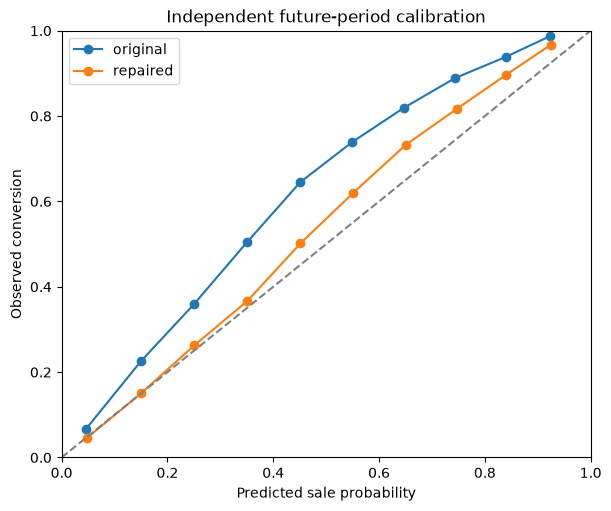

Saved verified replacement bundle and independent diagnostics: /Users/ecilteodoro/Library/Mobile Documents/com~apple~CloudDocs/UWF/2026-8/IDC6940/code-repo/data/training/calibration_repair


In [7]:
fig,ax=plt.subplots(figsize=(6,5),layout='constrained')
reliability=[]
for name,column in [('original','old_probability'),('repaired','repaired_probability')]:
    temp=predictions.copy();temp['bin']=pd.cut(temp[column],np.linspace(0,1,11),include_lowest=True)
    table=temp.groupby('bin',observed=True).agg(n=('sold','size'),predicted=(column,'mean'),observed=('sold','mean')).reset_index()
    table['model']=name;reliability.append(table)
    ax.plot(table.predicted,table.observed,'o-',label=name)
ax.plot([0,1],[0,1],'--',color='gray');ax.set(xlim=(0,1),ylim=(0,1),xlabel='Predicted sale probability',ylabel='Observed conversion',title='Independent future-period calibration')
ax.legend();fig.savefig(OUT/'independent_calibration.png',dpi=180);plt.show()
pd.concat(reliability).to_csv(OUT/'independent_reliability.csv',index=False)
# Save a compatible replacement bundle, retaining the original price estimator.
updated=original.copy();updated['classifier']=repaired
updated['classifier_name']=str(choice.variant)+'_'+str(choice.correction)
updated['calibration_repair']='04_probability_calibration.ipynb'
with (OUT/'selected_models.pkl').open('wb') as f:cloudpickle.dump(updated,f)
with (OUT/'selected_models.pkl').open('rb') as f:loaded=cloudpickle.load(f)
probe=features(validation.head(30))
assert np.allclose(loaded['classifier'].predict_proba(probe),repaired.predict_proba(probe))
assert predictions.repaired_probability.between(0,1).all()
assert len(predictions[['seed','vehicle_id']].drop_duplicates())==len(predictions)
summary=dict(selected_variant=str(choice.variant),selected_correction=str(choice.correction),seeds=SEEDS,
  calibration_cut=str(calibration_cut.date()),future_cut=str(validation.auction_date.max().date()),
  original_calendar_log_odds_per_year=trend*365.25,
  generator='Original calibration frozen; independent draws only',retired_test_used_for_tuning=False,
  scope='Five independent samples, fixed predictive models; not full 30-replication refit study')
(OUT/'repair_metadata.json').write_text(json.dumps(summary,indent=2)+'\n')
print('Saved verified replacement bundle and independent diagnostics:',OUT.resolve())


## Representative simulation calibration and fresh final verification

The first-stage improvement was insufficient, especially for fleet/lease records. Seeds 16940–16944 above are now **diagnostic/development evidence**, not the final confirmation set.

Use seed 26940 to fit corrections on an independent synthetic cohort from the target calendar window and seed 26941 to select raw/global/group correction by log loss. Do not change the trained base model or generator. Lock the chosen correction, then evaluate seeds 36940–36944 exactly once. All coefficients use observed synthetic outcomes; latent probabilities remain evaluation-only.

This stage requires representative labeled simulations from the target calendar distribution. It tests generalization to independent vehicles and shocks in that same distribution, **not forecasting an entirely unseen calendar regime**. It does not justify transferring a simulation correction directly to real auctions. The retired original test outcomes do not enter these fits.


In [8]:
development, _ = generate_independent(26940)
selection_new, _ = generate_independent(26941)
development=development.loc[development.auction_date.gt(validation.auction_date.max())].copy()
selection_new=selection_new.loc[selection_new.auction_date.gt(validation.auction_date.max())].copy()
q_development=selected.predict_proba(features(development))[:,1]
q_selection=selected.predict_proba(features(selection_new))[:,1]
final_candidates={}; final_selection_rows=[]
for mode in ['raw','global_sigmoid','group_sigmoid']:
    adjustment=fit_correction(mode,q_development,development.seller_group,development.sold)
    final_candidates[mode]=adjustment
    q=correct(adjustment,q_selection,selection_new.seller_group)
    final_selection_rows.append(dict(correction=mode,log_loss=log_loss(selection_new.sold,q),
          brier=brier_score_loss(selection_new.sold,q),predicted=q.mean(),observed=selection_new.sold.mean()))
final_selection=pd.DataFrame(final_selection_rows).sort_values('log_loss')
final_mode=final_selection.iloc[0].correction
final_model=CalibratedSaleModel(selected,final_candidates[final_mode])
final_selection.to_csv(OUT/'representative_development_selection.csv',index=False)
display(final_selection)
print('Final correction locked:',final_mode)


,correction,log_loss,brier,predicted,observed
2,group_sigmoid,0.512290,0.170667,0.505321,0.51502
1,global_sigmoid,0.514099,0.171448,0.505231,0.51502
0,raw,0.521523,0.174285,0.468278,0.51502


Final correction locked: group_sigmoid


In [9]:
FINAL_SEEDS=list(range(36940,36945))
final_rows=[]; final_predictions=[]
for seed in FINAL_SEEDS:
    generated, latent=generate_independent(seed)
    future=generated.loc[generated.auction_date.gt(validation.auction_date.max())].copy()
    x=features(future);q_original=original['classifier'].predict_proba(x)[:,1];q_final=final_model.predict_proba(x)[:,1]
    prices=original['price_predict'](original['price_model'],x)[0]
    true=latent.set_index('vehicle_id').loc[future.vehicle_id,'true_sale_probability_given_latents'].to_numpy()
    t=future[['vehicle_id','auction_date','seller_group','sold','price']].copy()
    t['seed']=seed;t['original_probability']=q_original;t['calibrated_probability']=q_final
    t['true_probability_given_latents']=true;t['predicted_price']=prices
    final_predictions.append(t)
    for name,q in [('original',q_original),('calibrated',q_final)]:
        for group in ['all','dealer','fleet_lease']:
            use=np.ones(len(t),dtype=bool) if group=='all' else t.seller_group.eq(group).to_numpy()
            yy=t.sold.to_numpy()[use];prob=q[use]
            final_rows.append(dict(seed=seed,model=name,group=group,n=int(use.sum()),predicted=prob.mean(),observed=yy.mean(),
                 true_mean=true[use].mean(),calibration_bias=prob.mean()-yy.mean(),log_loss=log_loss(yy,prob),
                 brier=brier_score_loss(yy,prob),gross_bias=float(np.mean(prob*prices[use]-t.price.fillna(0).to_numpy()[use]))))
final_results=pd.DataFrame(final_rows)
final_predictions=pd.concat(final_predictions,ignore_index=True)
final_results.to_csv(OUT/'final_independent_metrics.csv',index=False)
final_predictions.to_csv(OUT/'final_independent_predictions.csv',index=False)
final_aggregate=final_results.groupby(['model','group'])[['predicted','observed','true_mean','calibration_bias','log_loss','brier','gross_bias']].mean()
final_aggregate.to_csv(OUT/'final_mean_replication_metrics.csv')
display(final_aggregate)


predicted  observed  true_mean  calibration_bias  \
model      group                                                           
calibrated all           0.506789  0.509479   0.509478         -0.002691   
           dealer        0.321006  0.316496   0.317503          0.004511   
           fleet_lease   0.699036  0.709191   0.708139         -0.010155   
original   all           0.383644  0.509479   0.509478         -0.125836   
           dealer        0.240143  0.316496   0.317503         -0.076353   
           fleet_lease   0.532140  0.709191   0.708139         -0.177052   

                        log_loss     brier   gross_bias  
model      group                                         
calibrated all          0.515261  0.172003   -22.484515  
           dealer       0.501135  0.167739    59.399242  
           fleet_lease  0.529881  0.176416  -107.283092  
original   all          0.559961  0.191054 -1192.750151  
           dealer       0.517960  0.174605  -559.336095  
           fleet_lease  0.603433  0.208079 -1848.286466

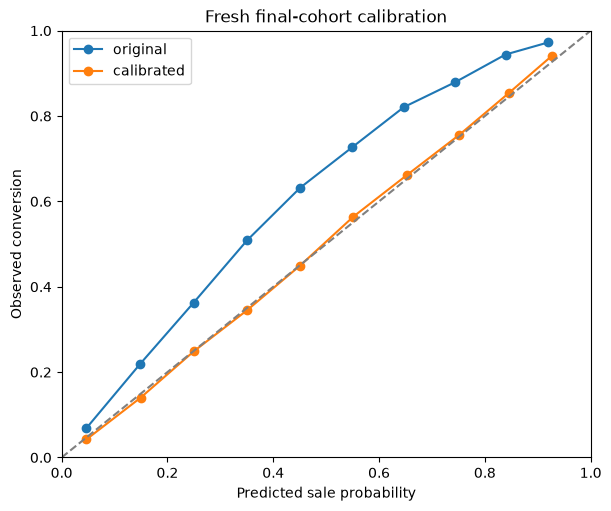

Final model and separately seeded verification artifacts saved.


In [10]:
fig,ax=plt.subplots(figsize=(6,5),layout='constrained')
final_reliability=[]
for name,column in [('original','original_probability'),('calibrated','calibrated_probability')]:
    t=final_predictions.copy();t['bin']=pd.cut(t[column],np.linspace(0,1,11),include_lowest=True)
    table=t.groupby('bin',observed=True).agg(n=('sold','size'),predicted=(column,'mean'),observed=('sold','mean')).reset_index()
    table['model']=name;final_reliability.append(table)
    ax.plot(table.predicted,table.observed,'o-',label=name)
ax.plot([0,1],[0,1],'--',color='gray');ax.set(xlim=(0,1),ylim=(0,1),xlabel='Predicted sale probability',ylabel='Observed conversion',title='Fresh final-cohort calibration')
ax.legend();fig.savefig(OUT/'final_independent_calibration.png',dpi=180);plt.show()
pd.concat(final_reliability).to_csv(OUT/'final_independent_reliability.csv',index=False)
updated=original.copy();updated['classifier']=final_model
updated['classifier_name']=str(choice.variant)+'_'+str(final_mode)
updated['calibration_repair']='04_probability_calibration.ipynb'
updated['calibration_population']='Independent synthetic labeled target-calendar cohorts; not unseen-regime forecasting'
with (OUT/'selected_models.pkl').open('wb') as f:cloudpickle.dump(updated,f)
correction_coefficients=[]
for group,m in final_candidates[final_mode].get('models',{}).items():
    correction_coefficients.append(dict(group=group,intercept=float(m.intercept_[0]),logit_slope=float(m.coef_[0,0])))
pd.DataFrame(correction_coefficients).to_csv(OUT/'probability_correction_coefficients.csv',index=False)
summary.update(final_correction=str(final_mode),calibration_seed=26940,selection_seed=26941,final_evaluation_seeds=FINAL_SEEDS,
  calibration_population=updated['calibration_population'],diagnostic_seeds=SEEDS)
(OUT/'repair_metadata.json').write_text(json.dumps(summary,indent=2)+'\n')
assert final_predictions.calibrated_probability.between(0,1).all()
assert set(FINAL_SEEDS).isdisjoint(SEEDS+[26940,26941])
print('Final model and separately seeded verification artifacts saved.')


# Current probability calibration

Use `data/training/calibration_repair/selected_models.pkl` for the current model bundle. It retains the original price model and replaces the sale classifier. The compatible feature interface retains calendar_days, but the revised sale estimator excludes the linear time term.

The original time term imposed -0.280 log odds per year. Removing it helped but did not resolve fleet/lease bias. Seller-group sigmoid correction was fitted on independent target-period synthetic outcomes (seed 26940) and selected with seed 26941. No latent probabilities or original test outcomes entered those fits.

Final verification used seeds 36940–36944, each generating 50,000 vehicles. Evaluation used dates after 2009-05-27. Mean replication predicted conversion improved from 38.36% to 50.68%, versus 50.95% observed. Brier score improved from 0.1911 to 0.1720; gross-proceeds bias improved from -$1,193 to -$22 per vehicle. Residual dealer bias is +0.45 percentage points and fleet/lease bias -1.02 points.

This verifies independent-cohort calibration within the same simulated target calendar distribution. It relies on representative labeled simulations; it is not evidence of forecasting unseen calendar regimes or live-auction performance. Generator parameters were frozen. The five-cohort evaluation is not the planned 30-replication policy study with model refits.

The `final_*` files contain final confirmation results. Earlier `independent_*` files retain first-stage diagnostic results and are not the final model. The model bundle was reloaded in a fresh Python process and matched saved predictions for dealer-only, fleet-only, and mixed batches. Source asset hashes remain unchanged.
